# Predictive Modelling Script

## Import Libraries

In [1]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from scipy.stats import ks_2samp
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve
import scikitplot as skplt
import warnings

## Set Random State

In [2]:
global rand_state
rand_state = 29


## Import Dataset

In [3]:
# Import the calculated features dataset
all_features = pd.read_csv("../Feature_Generation/calculated_features/combined features.csv")
selected_features = pd.read_csv("../Information_Value/selected_features/combined_selected_features.csv")

### Train-Test Split for Model Training

In [4]:
# Splitting all variables to explanatory and target variables, and training and test sets
all_X = all_features[(all_features.dtypes!=object)[(all_features.dtypes!=object)].index].iloc[:,:-1]
all_y = all_features['target']

all_X_train, all_X_test, all_y_train, all_y_test = train_test_split(all_X, all_y, test_size=0.3, random_state=rand_state)

scaler = StandardScaler()
all_X_train_scaled, all_X_test_scaled = scaler.fit_transform(all_X_train), scaler.transform(all_X_test)

In [5]:
# Splitting selected variables to explanatory and target variables, and training and test sets
selected_X = selected_features[(selected_features.dtypes!=object)[(selected_features.dtypes!=object)].index].iloc[:,:-1]
selected_y = selected_features['target']

selected_X_train, selected_X_test, selected_y_train, selected_y_test = train_test_split(selected_X, selected_y, test_size=0.3, random_state=rand_state)

scaler = StandardScaler()
selected_X_train_scaled, selected_X_test_scaled = scaler.fit_transform(selected_X_train), scaler.transform(selected_X_test)

## Model Training

#### 1) Logistic Regression

In [6]:
# Selecting the best logistic regression model from specified parameters
lr_GS = GridSearchCV(LogisticRegression(), 
                     {"C": [0.001, 0.01, 0.1, 1, 10, 100], 
                      "penalty": ['l2'],
                      "solver": ['lbfgs', 'liblinear']})

lr_GS = lr_GS.fit(selected_X_train_scaled, selected_y_train)
lr = lr_GS.best_estimator_
lr.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on logistic regression model
lr_trainpred = lr.predict(selected_X_train_scaled)
lr_testpred = lr.predict(selected_X_test_scaled)

In [7]:
# List out the index of an element's occurance in a given list
def getAllIndex(element, list):
    result = []
    count = 0
    for i in list:
        if i == element:
            result.append(count)
        count += 1
    return result

train_0_index = getAllIndex(0, selected_y_train)
train_1_index = getAllIndex(1, selected_y_train)
test_0_index = getAllIndex(0, selected_y_test)
test_1_index = getAllIndex(1, selected_y_test)

In [8]:
# Create dataframe to store model performances
results_df = pd.DataFrame({'Model':[], 'Model Code': [],
                           "Train Accuracy": [], "Train Precision": [], "Train Recall": [], "Train ROC AUC": [], "Train KS Stat": [], 
                           "Test Accuracy": [], "Test Precision": [], "Test Recall": [], "Test ROC AUC": [], "Test KS Stat": []})

In [9]:
# Record logistic regression model performance
results_df.loc[len(results_df)] = {'Model':'Logistic Regression', 
                                   'Model Code': lr,
                                   
                                   "Train Accuracy": accuracy_score(selected_y_train, lr_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, lr_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, lr_trainpred), 
                                   "Train ROC AUC": roc_auc_score(selected_y_train, lr_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(lr_trainpred).iloc[train_0_index], pd.Series(lr_trainpred).iloc[train_1_index])[0], 

                                   "Test Accuracy": accuracy_score(selected_y_test, lr_testpred), 
                                   "Test Precision": precision_score(selected_y_test, lr_testpred), 
                                   "Test Recall": recall_score(selected_y_test, lr_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, lr_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(lr_testpred).iloc[test_0_index], pd.Series(lr_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model                                          Logistic Regression
Model Code         LogisticRegression(C=0.001, solver='liblinear')
Train Accuracy                                            0.794286
Train Precision                                           0.765957
Train Recall                                              0.837209
Train ROC AUC                                             0.795009
Train KS Stat                                             0.590018
Test Accuracy                                             0.733333
Test Precision                                              0.6875
Test Recall                                               0.868421
Test ROC AUC                                              0.731508
Test KS Stat                                              0.463016
Name: 0, dtype: object

#### 2) Decision Tree Classifier

In [10]:
# Selecting the best decision tree model from specified parameters
dt_GS = GridSearchCV(DecisionTreeClassifier(), 
                     {"criterion": ['gini', 'entropy'], 
                      "max_depth": [2,4,6,8,10,12]})

dt_GS = dt_GS.fit(selected_X_train_scaled, selected_y_train)
dt = dt_GS.best_estimator_
dt.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on decision tree model
dt_trainpred = dt.predict(selected_X_train_scaled)
dt_testpred = dt.predict(selected_X_test_scaled)

In [11]:
# Record decision tree model performance
results_df.loc[len(results_df)] = {'Model':'Decision Tree Classifier', 
                                   'Model Code': dt,

                                   "Train Accuracy": accuracy_score(selected_y_train, dt_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, dt_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, dt_trainpred),
                                   "Train ROC AUC": roc_auc_score(selected_y_train, dt_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(dt_trainpred).iloc[train_0_index], pd.Series(dt_trainpred).iloc[train_1_index])[0],

                                   "Test Accuracy": accuracy_score(selected_y_test, dt_testpred), 
                                   "Test Precision": precision_score(selected_y_test, dt_testpred), 
                                   "Test Recall": recall_score(selected_y_test, dt_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, dt_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(dt_testpred).iloc[test_0_index], pd.Series(dt_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model                         Decision Tree Classifier
Model Code         DecisionTreeClassifier(max_depth=6)
Train Accuracy                                0.908571
Train Precision                                0.87234
Train Recall                                  0.953488
Train ROC AUC                                 0.909328
Train KS Stat                                 0.818657
Test Accuracy                                 0.653333
Test Precision                                0.676471
Test Recall                                   0.605263
Test ROC AUC                                  0.653983
Test KS Stat                                  0.307966
Name: 1, dtype: object

#### 3) Random Forest Classifier

In [12]:
# Selecting the best random forest model from specified parameters
rf_GS = GridSearchCV(RandomForestClassifier(), 
                     {'n_estimators': [100, 500, 1000], 
                      "max_depth": [2, 5, 10]})

rf_GS = rf_GS.fit(selected_X_train_scaled, selected_y_train)
rf = rf_GS.best_estimator_
rf.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on random forest model
rf_trainpred = rf.predict(selected_X_train_scaled)
rf_testpred = rf.predict(selected_X_test_scaled)

In [13]:
# Record random forest model performance
results_df.loc[len(results_df)] = {'Model':'Random Forest Classifier', 
                                   'Model Code': rf,
                                   
                                   "Train Accuracy": accuracy_score(selected_y_train, rf_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, rf_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, rf_trainpred),
                                   "Train ROC AUC": roc_auc_score(selected_y_train, rf_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(rf_trainpred).iloc[train_0_index], pd.Series(rf_trainpred).iloc[train_1_index])[0],

                                   "Test Accuracy": accuracy_score(selected_y_test, rf_testpred), 
                                   "Test Precision": precision_score(selected_y_test, rf_testpred), 
                                   "Test Recall": recall_score(selected_y_test, rf_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, rf_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(rf_testpred).iloc[test_0_index], pd.Series(rf_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model                                       Random Forest Classifier
Model Code         (DecisionTreeClassifier(max_depth=5, max_featu...
Train Accuracy                                              0.982857
Train Precision                                             0.977011
Train Recall                                                0.988372
Train ROC AUC                                                0.98295
Train KS Stat                                                 0.9659
Test Accuracy                                               0.746667
Test Precision                                              0.731707
Test Recall                                                 0.789474
Test ROC AUC                                                0.746088
Test KS Stat                                                0.492176
Name: 2, dtype: object

#### 4) Naive Bayes Classifier

In [14]:
# Selecting the best naive bayes model from specified parameters
nb_GS = GridSearchCV(GaussianNB(), 
                     {'var_smoothing': np.logspace(0,-9, num=100)})

nb_GS = nb_GS.fit(selected_X_train_scaled, selected_y_train)
nb = nb_GS.best_estimator_
nb.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on naive bayes model
nb_trainpred = nb.predict(selected_X_train_scaled)
nb_testpred = nb.predict(selected_X_test_scaled)

In [15]:
# Record naive bayes model performance
results_df.loc[len(results_df)] = {'Model':'Naive Bayes Classifier', 
                                   'Model Code': nb,
                                   
                                   "Train Accuracy": accuracy_score(selected_y_train, nb_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, nb_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, nb_trainpred),
                                   "Train ROC AUC": roc_auc_score(selected_y_train, nb_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(nb_trainpred).iloc[train_0_index], pd.Series(nb_trainpred).iloc[train_1_index])[0],

                                   "Test Accuracy": accuracy_score(selected_y_test, nb_testpred), 
                                   "Test Precision": precision_score(selected_y_test, nb_testpred), 
                                   "Test Recall": recall_score(selected_y_test, nb_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, nb_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(nb_testpred).iloc[test_0_index], pd.Series(nb_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model                                     Naive Bayes Classifier
Model Code         GaussianNB(var_smoothing=0.02848035868435802)
Train Accuracy                                          0.737143
Train Precision                                         0.681818
Train Recall                                            0.872093
Train ROC AUC                                           0.739417
Train KS Stat                                           0.478835
Test Accuracy                                           0.693333
Test Precision                                          0.647059
Test Recall                                             0.868421
Test ROC AUC                                            0.690967
Test KS Stat                                            0.381935
Name: 3, dtype: object

#### 5) K-Nearest Neighbors (KNN) Classifier

In [16]:
# Selecting the best k-nearest neighbors model from specified parameters
knn_GS = GridSearchCV(KNeighborsClassifier(), 
                     {'n_neighbors': [3, 5, 7, 9],
                      'weights':['uniform', 'distance'],
                      'leaf_size':[15,20]})

knn_GS = knn_GS.fit(selected_X_train_scaled, selected_y_train)
knn = knn_GS.best_estimator_
knn.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on k-nearest neighbors model
knn_trainpred = knn.predict(selected_X_train_scaled)
knn_testpred = knn.predict(selected_X_test_scaled)

In [17]:
# Record k-nearest neighbors model performance
results_df.loc[len(results_df)] = {'Model':'K-Nearest Neighbors (KNN) Classifier', 
                                   'Model Code': knn,
                                   
                                   "Train Accuracy": accuracy_score(selected_y_train, knn_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, knn_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, knn_trainpred),
                                   "Train ROC AUC": roc_auc_score(selected_y_train, knn_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(knn_trainpred).iloc[train_0_index], pd.Series(knn_trainpred).iloc[train_1_index])[0],

                                   "Test Accuracy": accuracy_score(selected_y_test, knn_testpred), 
                                   "Test Precision": precision_score(selected_y_test, knn_testpred), 
                                   "Test Recall": recall_score(selected_y_test, knn_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, knn_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(knn_testpred).iloc[test_0_index], pd.Series(knn_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model                           K-Nearest Neighbors (KNN) Classifier
Model Code         KNeighborsClassifier(leaf_size=15, n_neighbors=7)
Train Accuracy                                              0.811429
Train Precision                                             0.778947
Train Recall                                                0.860465
Train ROC AUC                                               0.812255
Train KS Stat                                                0.62451
Test Accuracy                                                   0.76
Test Precision                                              0.727273
Test Recall                                                 0.842105
Test ROC AUC                                                 0.75889
Test KS Stat                                                0.517781
Name: 4, dtype: object

#### 6) Support Vector Machine (SVM) Classifier

In [18]:
# Selecting the best support vector machine model from specified parameters
svm_GS = GridSearchCV(SVC(), 
                     {'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
                      'C': [100, 10, 1.0, 0.1, 0.001]})

svm_GS = svm_GS.fit(selected_X_train_scaled, selected_y_train)
svm = svm_GS.best_estimator_
svm.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on support vector machine model
svm_trainpred = svm.predict(selected_X_train_scaled)
svm_testpred = svm.predict(selected_X_test_scaled)

In [19]:
# Record support vector machine model performance
results_df.loc[len(results_df)] = {'Model':'Support Vector Machine (SVM) Classifier', 
                                   'Model Code': svm,
                                   
                                   "Train Accuracy": accuracy_score(selected_y_train, svm_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, svm_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, svm_trainpred),
                                   "Train ROC AUC": roc_auc_score(selected_y_train, svm_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(svm_trainpred).iloc[train_0_index], pd.Series(svm_trainpred).iloc[train_1_index])[0],

                                   "Test Accuracy": accuracy_score(selected_y_test, svm_testpred), 
                                   "Test Precision": precision_score(selected_y_test, svm_testpred), 
                                   "Test Recall": recall_score(selected_y_test, svm_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, svm_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(svm_testpred).iloc[test_0_index], pd.Series(svm_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model              Support Vector Machine (SVM) Classifier
Model Code                    SVC(C=0.1, kernel='sigmoid')
Train Accuracy                                         0.8
Train Precision                                   0.774194
Train Recall                                      0.837209
Train ROC AUC                                     0.800627
Train KS Stat                                     0.601254
Test Accuracy                                         0.76
Test Precision                                    0.708333
Test Recall                                       0.894737
Test ROC AUC                                      0.758179
Test KS Stat                                      0.516358
Name: 5, dtype: object

#### 7) Extreme Gradient Boosting (XGB) Classifier

In [20]:
# Selecting the best extreme gradient boosting model from specified parameters
xgb_GS = GridSearchCV(XGBClassifier(), 
                     {'max_depth': [2, 5, 10],
                      'n_estimators': range(60, 220, 40),
                      'learning_rate': [0.1, 0.01]})

xgb_GS = xgb_GS.fit(selected_X_train_scaled, selected_y_train)
xgb = xgb_GS.best_estimator_
xgb.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on extreme gradient boosting model
xgb_trainpred = xgb.predict(selected_X_train_scaled)
xgb_testpred = xgb.predict(selected_X_test_scaled)

In [21]:
# Record extreme gradient boosting model performance
results_df.loc[len(results_df)] = {'Model':'Extreme Gradient Boosting (XGB) Classifier', 
                                   'Model Code': xgb,
                                   
                                   "Train Accuracy": accuracy_score(selected_y_train, xgb_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, xgb_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, xgb_trainpred),
                                   "Train ROC AUC": roc_auc_score(selected_y_train, xgb_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(xgb_trainpred).iloc[train_0_index], pd.Series(xgb_trainpred).iloc[train_1_index])[0],

                                   "Test Accuracy": accuracy_score(selected_y_test, xgb_testpred), 
                                   "Test Precision": precision_score(selected_y_test, xgb_testpred), 
                                   "Test Recall": recall_score(selected_y_test, xgb_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, xgb_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(xgb_testpred).iloc[test_0_index], pd.Series(xgb_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model                     Extreme Gradient Boosting (XGB) Classifier
Model Code         XGBClassifier(base_score=None, booster=None, c...
Train Accuracy                                              0.948571
Train Precision                                             0.932584
Train Recall                                                0.965116
Train ROC AUC                                                0.94885
Train KS Stat                                               0.897701
Test Accuracy                                                   0.76
Test Precision                                              0.727273
Test Recall                                                 0.842105
Test ROC AUC                                                 0.75889
Test KS Stat                                                0.517781
Name: 6, dtype: object

#### 8) Light Gradient Boosting Machine (LGBM) Classifier

In [22]:
# Selecting the best light gradient boosting machine model from specified parameters
lgbm_GS = GridSearchCV(LGBMClassifier(), 
                     {'max_depth': [2, 5, 10],
                      'n_estimators': range(60, 220, 40),
                      'learning_rate': [0.1, 0.01]})

lgbm_GS = lgbm_GS.fit(selected_X_train_scaled, selected_y_train)
lgbm = lgbm_GS.best_estimator_
lgbm.fit(selected_X_train_scaled, selected_y_train)

# Predicting based on light gradient boosting machine model
lgbm_trainpred = lgbm.predict(selected_X_train_scaled)
lgbm_testpred = lgbm.predict(selected_X_test_scaled)

In [23]:
# Record light gradient boosting machine model performance
results_df.loc[len(results_df)] = {'Model':'Light Gradient Boosting Machine (LGBM) Classifier', 
                                   'Model Code': lgbm,

                                   "Train Accuracy": accuracy_score(selected_y_train, lgbm_trainpred), 
                                   "Train Precision": precision_score(selected_y_train, lgbm_trainpred), 
                                   "Train Recall": recall_score(selected_y_train, lgbm_trainpred),
                                   "Train ROC AUC": roc_auc_score(selected_y_train, lgbm_trainpred), 
                                   "Train KS Stat": ks_2samp(pd.Series(lgbm_trainpred).iloc[train_0_index], pd.Series(lgbm_trainpred).iloc[train_1_index])[0],

                                   "Test Accuracy": accuracy_score(selected_y_test, lgbm_testpred), 
                                   "Test Precision": precision_score(selected_y_test, lgbm_testpred), 
                                   "Test Recall": recall_score(selected_y_test, lgbm_testpred),
                                   "Test ROC AUC": roc_auc_score(selected_y_test, lgbm_testpred), 
                                   "Test KS Stat": ks_2samp(pd.Series(lgbm_testpred).iloc[test_0_index], pd.Series(lgbm_testpred).iloc[test_1_index])[0]} 

results_df.loc[len(results_df)-1]

Model              Light Gradient Boosting Machine (LGBM) Classifier
Model Code              LGBMClassifier(max_depth=2, n_estimators=60)
Train Accuracy                                              0.931429
Train Precision                                             0.911111
Train Recall                                                0.953488
Train ROC AUC                                                 0.9318
Train KS Stat                                               0.863601
Test Accuracy                                                    0.8
Test Precision                                              0.780488
Test Recall                                                 0.842105
Test ROC AUC                                                0.799431
Test KS Stat                                                0.598862
Name: 7, dtype: object

## Model Evaluation

In [24]:
# Display performances of all models
results_df

,Model,Model Code,Train Accuracy,Train Precision,Train Recall,Train ROC AUC,Train KS Stat,Test Accuracy,Test Precision,Test Recall,Test ROC AUC,Test KS Stat
0,Logistic Regression,"LogisticRegression(C=0.001, solver='liblinear')",0.794286,0.765957,0.837209,0.795009,0.590018,0.733333,0.687500,0.868421,0.731508,0.463016
1,Decision Tree Classifier,DecisionTreeClassifier(max_depth=6),0.908571,0.872340,0.953488,0.909328,0.818657,0.653333,0.676471,0.605263,0.653983,0.307966
2,Random Forest Classifier,"(DecisionTreeClassifier(max_depth=5, max_featu...",0.982857,0.977011,0.988372,0.982950,0.965900,0.746667,0.731707,0.789474,0.746088,0.492176
3,Naive Bayes Classifier,GaussianNB(var_smoothing=0.02848035868435802),0.737143,0.681818,0.872093,0.739417,0.478835,0.693333,0.647059,0.868421,0.690967,0.381935
4,K-Nearest Neighbors (KNN) Classifier,"KNeighborsClassifier(leaf_size=15, n_neighbors=7)",0.811429,0.778947,0.860465,0.812255,0.624510,0.760000,0.727273,0.842105,0.758890,0.517781
5,Support Vector Machine (SVM) Classifier,"SVC(C=0.1, kernel='sigmoid')",0.800000,0.774194,0.837209,0.800627,0.601254,0.760000,0.708333,0.894737,0.758179,0.516358
6,Extreme Gradient Boosting (XGB) Classifier,"XGBClassifier(base_score=None, booster=None, c...",0.948571,0.932584,0.965116,0.948850,0.897701,0.760000,0.727273,0.842105,0.758890,0.517781
7,Light Gradient Boosting Machine (LGBM) Classifier,"LGBMClassifier(max_depth=2, n_estimators=60)",0.931429,0.911111,0.953488,0.931800,0.863601,0.800000,0.780488,0.842105,0.799431,0.598862


In [25]:
# Select top model based on ROC AUC test score
sorted_results_df = results_df.sort_values(by="Test ROC AUC", ascending=False)
sorted_results_df.reset_index(inplace=True)
sorted_results_df.drop("index", axis=1, inplace=True)

top_rocauc_model = sorted_results_df.iloc[0]
top_rocauc_model

Model              Light Gradient Boosting Machine (LGBM) Classifier
Model Code              LGBMClassifier(max_depth=2, n_estimators=60)
Train Accuracy                                              0.931429
Train Precision                                             0.911111
Train Recall                                                0.953488
Train ROC AUC                                                 0.9318
Train KS Stat                                               0.863601
Test Accuracy                                                    0.8
Test Precision                                              0.780488
Test Recall                                                 0.842105
Test ROC AUC                                                0.799431
Test KS Stat                                                0.598862
Name: 0, dtype: object

Score: 0.02743  	 Feature: min_numKeyPositionsAgainstNumOtherBusinessKeyPositions 
Score: 0.02400  	 Feature: max_numSecretaries 
Score: 0.00457  	 Feature: max_numActiveChargesAgainstNumOtherBusinessActiveCharges 
Score: 0.05829  	 Feature: max_numSubsidiary 
Score: -0.00686  	 Feature: max_recentYearIndividualFinancialSearchCount 
Score: -0.00000  	 Feature: max_numSubsidiaryAgainstNumOtherBusinessSubsidiary 
Score: 0.04229  	 Feature: max_recentYearIndividualCommercialRetailSearchCount 
Score: 0.00000  	 Feature: max_recentYearIndividualLegalSearchCount 
Score: 0.07657  	 Feature: max_numPreviousCancelledBusinesses 
Score: 0.01257  	 Feature: max_numCurrentLiveBusinesses 
Score: 0.07086  	 Feature: max_numKeyPositions 
Score: 0.01486  	 Feature: max_recentYearIndividualCommercialSearchCount 
Score: -0.00000  	 Feature: min_numShareholdersAgainstNumOtherBusinessShareholders 
Score: 0.00000  	 Feature: min_recentYearIndividualLitigationSearchCount 
Score: -0.00229  	 Feature: max_rece

Text(0.5, 1.0, 'Feature Importance for Light Gradient Boosting Machine (LGBM) Classifier')

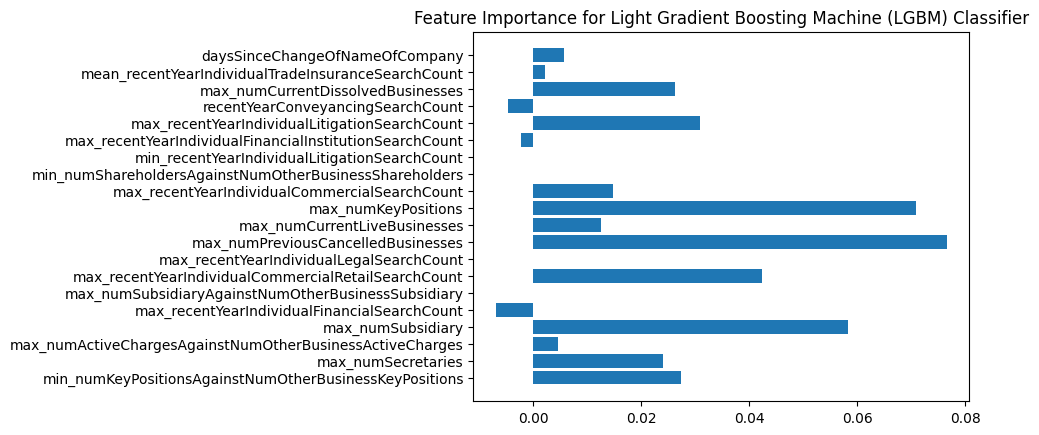

In [26]:
# Display feature importance of top ROC AUC model
warnings.filterwarnings("ignore")

results = permutation_importance(top_rocauc_model["Model Code"], selected_X_train_scaled, selected_y_train, scoring='accuracy')
importance = results.importances_mean
for c,i in zip(selected_X_train.columns, importance):
    print('Score: %.5f  \t Feature: %s ' % (i, c))

plt.barh(selected_X_train.columns, importance)
plt.title("Feature Importance for " + top_rocauc_model["Model"])

Text(0.5, 1.0, 'Confusion Matrix for Light Gradient Boosting Machine (LGBM) Classifier')

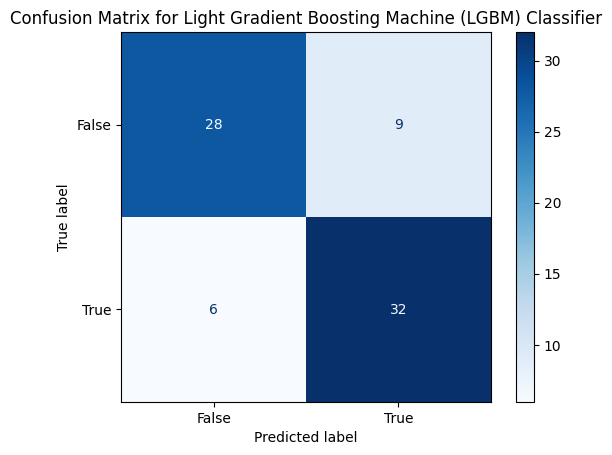

In [27]:
# Display confusion matrix of top ROC AUC model
from sklearn.metrics import confusion_matrix
confusion_matrix = confusion_matrix(selected_y_test, top_rocauc_model["Model Code"].predict(selected_X_test_scaled))
ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [False, True]).plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for " + top_rocauc_model["Model"])

Text(0.5, 1.0, 'KS Statistic Plot for Light Gradient Boosting Machine (LGBM) Classifier')

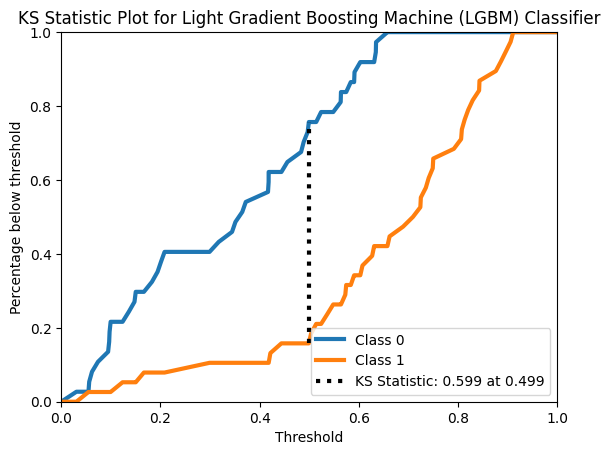

In [28]:
# Display KS statistic plot of top ROC AUC model
skplt.metrics.plot_ks_statistic(selected_y_test, top_rocauc_model["Model Code"].predict_proba(selected_X_test_scaled))
plt.title("KS Statistic Plot for " + top_rocauc_model["Model"])

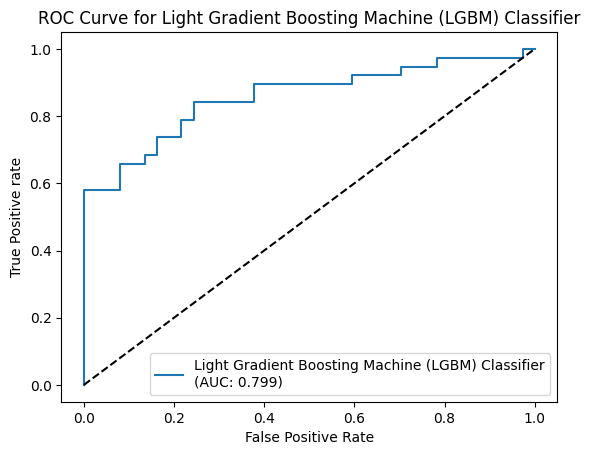

In [29]:
# Display ROC curve of top ROC AUC model
fpr, tpr, thresh = roc_curve(selected_y_test, top_rocauc_model["Model Code"].predict_proba(selected_X_test_scaled)[:,1], pos_label=1)
auc_score = roc_auc_score(selected_y_test, top_rocauc_model["Model Code"].predict(selected_X_test_scaled))

random_probs = [0 for i in range(len(selected_y_test))]
p_fpr, p_tpr, _ = roc_curve(selected_y_test, random_probs, pos_label=1)

plt.plot(fpr, tpr, label=f'%s\n(AUC: %.3f)'%(top_rocauc_model["Model"], auc_score))
plt.plot(p_fpr, p_tpr, linestyle='--', color='black')

plt.title('ROC Curve for ' +  top_rocauc_model["Model"])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.legend()

### Static Dashboard View of Results

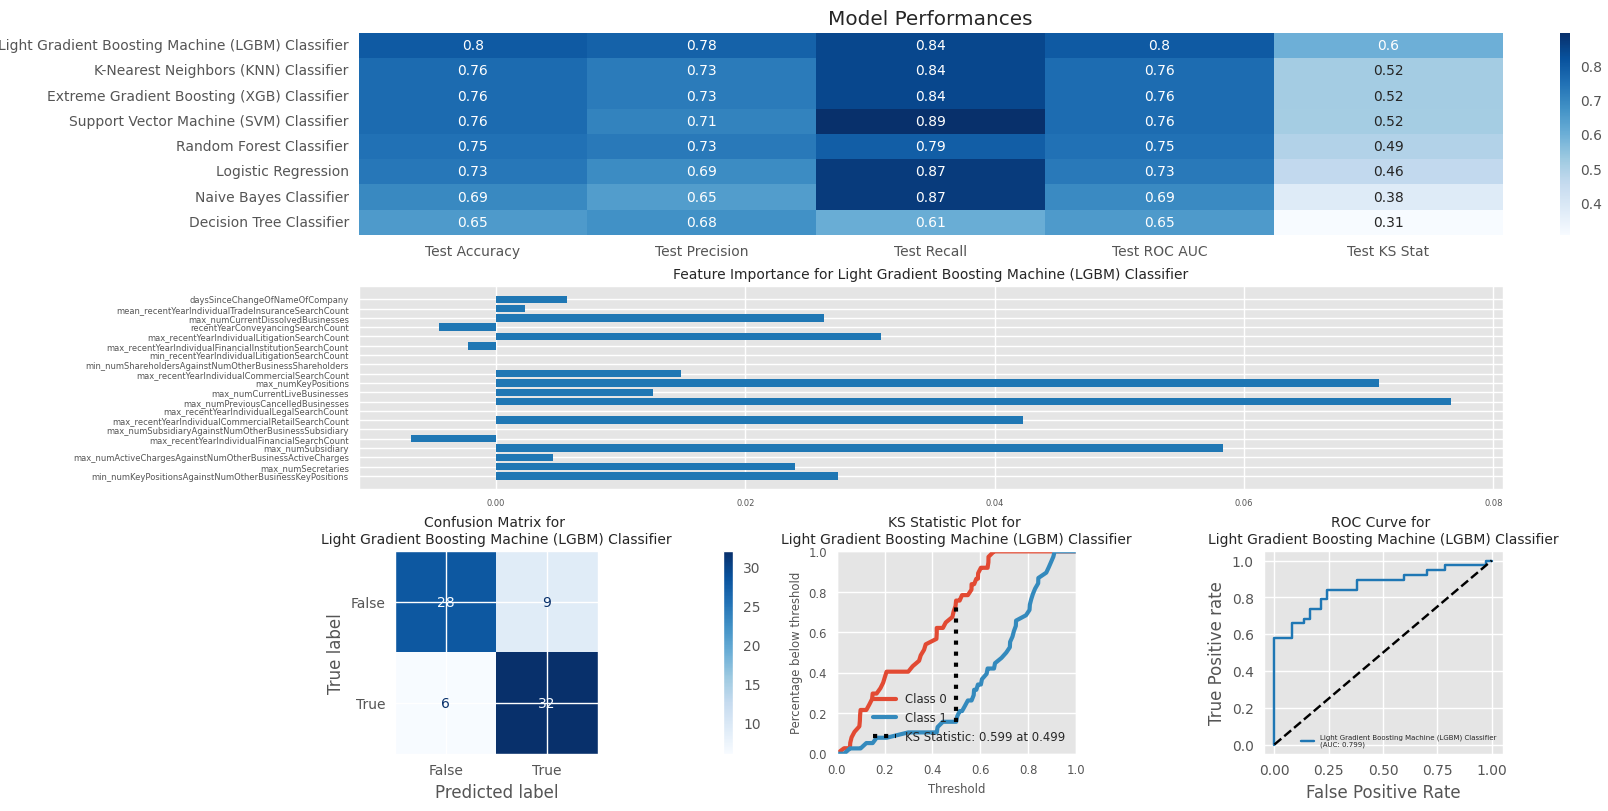

In [31]:
# Summary chart
import matplotlib.gridspec as gridspec
import seaborn as sns

with plt.style.context(("seaborn","ggplot")):
    fig = plt.figure(constrained_layout=True, figsize=(16,8))
    specs = gridspec.GridSpec(ncols=3, nrows=3, figure=fig)

    ax1 = fig.add_subplot(specs[0, :]) ## First Row
    ax2 = fig.add_subplot(specs[1, :]) ## Second Row
    ax3 = fig.add_subplot(specs[2, 0]) ## Third Row First Column
    ax4 = fig.add_subplot(specs[2, 1]) ## Third Row Second Column
    ax5 = fig.add_subplot(specs[2, 2]) ## Third Row Third Column

    ## First Graph -  Model Metrics
    display_df = sorted_results_df.set_index("Model")
    g1 = sns.heatmap(display_df[["Test Accuracy", "Test Precision", "Test Recall", "Test ROC AUC", "Test KS Stat"]],
                      annot=True, cmap='Blues', ax=ax1)
    ax1.set_title("Model Performances")

    ## Second Graph - Feature Importance
    ax2.barh(selected_X_train.columns, importance, color="tab:blue")
    ax2.tick_params(axis='both', which='major', labelsize=6)
    ax2.tick_params(axis='both', which='minor', labelsize=6)
    ax2.set_title("Feature Importance for " + top_rocauc_model["Model"], fontsize = 10)

    ## Third Graph - Confusion Matrix
    ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [False, True]).plot(cmap=plt.cm.Blues, ax=ax3)
    ax3.set_title("Confusion Matrix for \n" + top_rocauc_model["Model"], fontsize = 10)

    ## Fourth Graph - KS Statistic Plot
    skplt.metrics.plot_ks_statistic(selected_y_test, top_rocauc_model["Model Code"].predict_proba(selected_X_test_scaled), ax=ax4, text_fontsize="small")
    ax4.set_title("KS Statistic Plot for \n" + top_rocauc_model["Model"], fontsize = 10)

    ## Fifth Graph - ROC Curve
    ax5.plot(fpr, tpr, label=f'%s\n(AUC: %.3f)'%(top_rocauc_model["Model"], auc_score), color='tab:blue')
    ax5.plot(p_fpr, p_tpr, linestyle='--', color='black')

    ax5.set_title('ROC Curve for \n' +  top_rocauc_model["Model"], fontsize = 10)
    ax5.set_xlabel('False Positive Rate')
    ax5.set_ylabel('True Positive rate')
    ax5.legend(fontsize = 5)
